C file generated: frame_FFFFFF.c


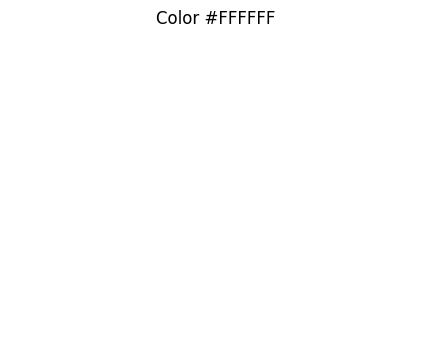

: 

In [ ]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# ==========================
# 配置
# ==========================
WIDTH = 160
HEIGHT = 120
COLOR_HEX = "FFFFFF"
C_ARRAY_NAME = f"frame_{COLOR_HEX}"
C_FILENAME = f"frame_{COLOR_HEX}.c"

# ==========================
# 1. 生成 RGB 图像
# ==========================
r = int(COLOR_HEX[0:2], 16)
g = int(COLOR_HEX[2:4], 16)
b = int(COLOR_HEX[4:6], 16)

# 创建 160x120 RGB 图像
rgb_img = np.zeros((HEIGHT, WIDTH, 3), dtype=np.uint8)
rgb_img[:, :, 0] = r
rgb_img[:, :, 1] = g
rgb_img[:, :, 2] = b

# ==========================
# 2. 转换为 YUV422
# ==========================
# YUV422 (YUYV) 每两个像素共享 U,V
def rgb_to_yuv422(rgb_img):
    H, W, _ = rgb_img.shape
    yuv422 = np.zeros((H, W*2), dtype=np.uint8)  # 每两个像素4字节
    for y in range(H):
        for x in range(0, W, 2):
            r0, g0, b0 = rgb_img[y, x]
            r1, g1, b1 = rgb_img[y, x+1]
            
            # RGB -> YUV (BT.601)
            Y0 = 0.299*r0 + 0.587*g0 + 0.114*b0
            Y1 = 0.299*r1 + 0.587*g1 + 0.114*b1
            U  = -0.169*r0 - 0.331*g0 + 0.5*b0 + 128
            V  = 0.5*r0 - 0.419*g0 - 0.081*b0 + 128
            
            yuv422[y, x*2+0] = int(Y0)
            yuv422[y, x*2+1] = int(U)
            yuv422[y, x*2+2] = int(Y1)
            yuv422[y, x*2+3] = int(V)
    return yuv422

yuv422_img = rgb_to_yuv422(rgb_img)

# ==========================
# 3. 写入 C 文件
# ==========================
with open(C_FILENAME, "w") as f:
    f.write(f"// Generated static frame ({WIDTH}x{HEIGHT})\n")
    f.write("#include <stdint.h>\n")
    f.write(f"const uint8_t {C_ARRAY_NAME}[{HEIGHT*WIDTH*2}] = {{\n")
    for i, val in enumerate(yuv422_img.flatten()):
        f.write(f"{val},")
        if (i+1) % 16 == 0:
            f.write("\n")
    f.write("};\n")

print(f"C file generated: {C_FILENAME}")

# ==========================
# 4. 反向验证显示
# ==========================
# 从 YUV422 转回 RGB 显示
def yuv422_to_rgb(yuv422_img):
    H, W2 = yuv422_img.shape
    W = W2 // 2
    rgb = np.zeros((H, W, 3), dtype=np.uint8)
    for y in range(H):
        for x in range(0, W, 2):
            Y0 = yuv422_img[y, x*2+0]
            U  = yuv422_img[y, x*2+1]
            Y1 = yuv422_img[y, x*2+2]
            V  = yuv422_img[y, x*2+3]
            
            # YUV -> RGB
            r0 = Y0 + 1.402*(V-128)
            g0 = Y0 - 0.344136*(U-128) - 0.714136*(V-128)
            b0 = Y0 + 1.772*(U-128)
            
            r1 = Y1 + 1.402*(V-128)
            g1 = Y1 - 0.344136*(U-128) - 0.714136*(V-128)
            b1 = Y1 + 1.772*(U-128)
            
            rgb[y, x, 0] = np.clip(r0, 0, 255)
            rgb[y, x, 1] = np.clip(g0, 0, 255)
            rgb[y, x, 2] = np.clip(b0, 0, 255)
            
            rgb[y, x+1, 0] = np.clip(r1, 0, 255)
            rgb[y, x+1, 1] = np.clip(g1, 0, 255)
            rgb[y, x+1, 2] = np.clip(b1, 0, 255)
    return rgb

rgb_back = yuv422_to_rgb(yuv422_img)
# Image.fromarray(rgb_back).show()

plt.figure(figsize=(6, 4))
plt.imshow(rgb_back)
plt.title(f"Color #{COLOR_HEX}")
plt.axis('off')
plt.show()
